# Laboratorio 3 · PaySim adaptado: regresión lineal y Holt-Winters
**Estadística para Analítica de Datos · UPTC · 2026-II · Prof. Duván Cataño** — David Nuncira, Juan Valderrama, Daniel Carrillo

Proyecto de modelación sobre la serie horaria de transacciones del Laboratorio 2. Ejecutar con *Run All* (la serie se lee de `results/hourly_series.csv`, igual que en el Laboratorio 2).

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent, Path('/content/laboratorio_3_paysim')] if (p/'src'/'pipeline.py').exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display, Markdown
except ImportError:
    display = print; Markdown = lambda s: s
from src.data import load_series, TARGET
from src.pipeline import run_all
from src.modeling import make_features, decompose, acf
from src.holtwinters import HoltWinters, HWConfig
from src.narrative import findings, hypotheses_text, diag_test
pd.options.display.float_format = '{:,.4f}'.format
plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.spines.top': False, 'axes.spines.right': False})
d = load_series(); o = run_all(d); sp = o['splits']
print(f"{len(d)} horas, {int(d[TARGET].sum()):,} transacciones | partición:", sp)

743 horas, 6,362,620 transacciones | partición: {'train_end': 455, 'val_end': 599, 'last': 743, 'first_supervised': 25}


## 1. Introducción y objetivo
Se pronostica `transacciones_hora` (conteo por hora simulada). Es un problema de **regresión** (la guía también lista regresión logística, que no aplica: no hay etiqueta de clase en el dataset adaptado). Modelos: **regresión lineal** (rezagos y variables temporales), cinco **baselines** y **Holt-Winters** (suavizamiento exponencial triple, periodo estacional 24 h).

## 2. Descripción de variables

In [2]:
display(pd.DataFrame({
    'variable': ['step', 'transacciones_hora', 'monto_total / promedio / mediano', 'fase_24', 'lag_1, lag_24', 'step + sin/cos(2πt/24, 2πt/12)'],
    'rol': ['índice temporal', 'OBJETIVO', 'NO predictor (se conoce al cierre de la hora: fuga)', 'perfil intradiario (step % 24)', 'predictores (conocidos en t-1)', 'predictores deterministas']}))
d.head()

,variable,rol
0,step,índice temporal
1,transacciones_hora,OBJETIVO
2,monto_total / promedio / mediano,NO predictor (se conoce al cierre de la hora: fuga)
3,fase_24,perfil intradiario (step % 24)
4,"lag_1, lag_24",predictores (conocidos en t-1)
5,"step + sin/cos(2πt/24, 2πt/12)",predictores deterministas


,step,transacciones_hora,monto_total,monto_promedio,monto_mediano,hora_dia,fase_24,ciclo
0,1,2708,"285,429,181.1500","105,402.2087","10,286.1700",1,1,1
1,2,1014,"85,921,604.0200","84,735.3097","10,522.7750",2,2,1
2,3,552,"43,293,884.4200","78,430.9500","14,091.9800",3,3,1
3,4,565,"72,910,028.5700","129,044.2984","7,800.5500",4,4,1
4,5,665,"45,548,089.7500","68,493.3680","6,902.5200",5,5,1


## 3. Limpieza y preprocesamiento
Validación de finitud, no negatividad, unicidad y continuidad de `step` (en `load_series`). No se imputa ni se recortan picos. Partición cronológica sin barajar.

In [3]:
x = make_features(d)
assert d.step.diff().dropna().eq(1).all() and d[TARGET].notna().all()
display(o['splits_table']); x.head()

,grupo,n,inicio,fin
0,train (HW usa 1-455),431,25,455
1,validacion,144,456,599
2,test,144,600,743


,step,transacciones_hora,lag_1,lag_24,lag_168,media_estacional_7,sin24,cos24,sin12,cos12
0,25,1598,"3,216.0000","2,708.0000",NaN,"2,708.0000",0.2588,0.9659,0.5000,0.8660
1,26,440,"1,598.0000","1,014.0000",NaN,"1,014.0000",0.5000,0.8660,0.8660,0.5000
2,27,41,440.0000,552.0000,NaN,552.0000,0.7071,0.7071,1.0000,0.0000
3,28,4,41.0000,565.0000,NaN,565.0000,0.8660,0.5000,0.8660,-0.5000
4,29,4,4.0000,665.0000,NaN,665.0000,0.9659,0.2588,0.5000,-0.8660


## 4. Análisis exploratorio (EDA)

,n,media,mediana,std,min,max,asimetria,curtosis_exceso,cv_pct,suma
0,743,"8,563.4186",529.0000,"13,388.6932",2,51352,1.3891,0.4629,156.3475,6362620


,inicio,fin,media,mediana,std,max
0,1,168,"11,489.1667",481.0000,"15,906.1278",51352
1,169,336,"16,991.6369","15,575.0000","14,897.7503",49083
2,337,504,"7,614.6488",460.5000,"12,498.0397",45155
3,505,672,"1,381.7560",27.0000,"2,475.8247",18631
4,673,743,935.9014,14.0000,"1,944.0808",8040


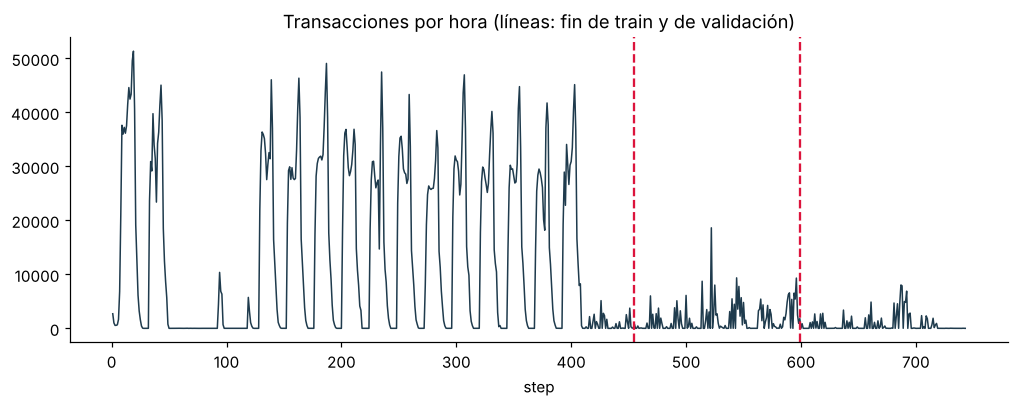

In [4]:
display(o['descriptive']); display(o['regimes'])
fig, ax = plt.subplots(); ax.plot(d.step, d[TARGET], lw=1, color='#1f3b4d')
for v in (sp['train_end'], sp['val_end']): ax.axvline(v, ls='--', color='crimson')
ax.set(title='Transacciones por hora (líneas: fin de train y de validación)', xlabel='step'); plt.show()

{'acf_1': 0.9235426141564032, 'acf_24': 0.7546011207852518, 'acf_168': 0.3860679227409596}


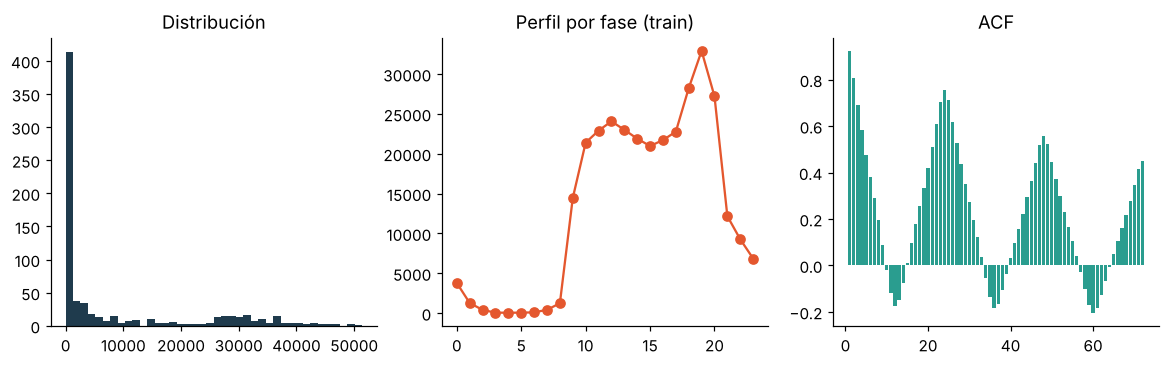

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
axs[0].hist(d[TARGET], bins=40, color='#1f3b4d'); axs[0].set_title('Distribución')
prof = d[d.step <= sp['train_end']].groupby('fase_24')[TARGET].mean(); axs[1].plot(prof, marker='o', color='#e4572e'); axs[1].set_title('Perfil por fase (train)')
a = o['acf']; axs[2].bar(a.lag[1:73], a.acf[1:73], color='#2a9d8f'); axs[2].set_title('ACF'); plt.show()
print(o['acf_resumen'])

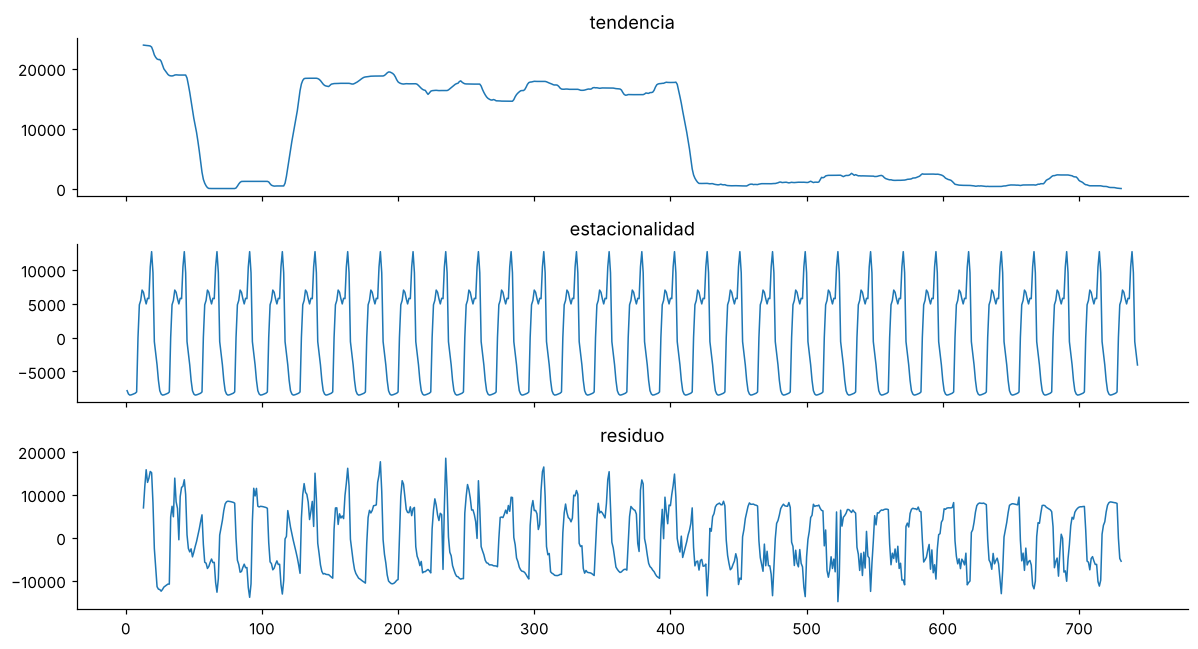

In [6]:
dc = decompose(d[TARGET].to_numpy(), 24, 'additive')   # descomposición clásica aditiva
fig, axs = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, c in zip(axs, ['tendencia', 'estacionalidad', 'residuo']): ax.plot(d.step, dc[c], lw=1); ax.set_title(c)
plt.tight_layout(); plt.show()

## 5. Pruebas de hipótesis e interpretación
α = 0,05, solo *train*. H1/H2: Wald con covarianza HAC (Newey-West, 24 rezagos); H3: Kruskal-Wallis entre las 24 fases; corrección de Holm. Ljung-Box de residuos de Holt-Winters como diagnóstico.

In [7]:
display(o['hypotheses']); display(o['coef_hac']); display(o['ljungbox_hw'])
for t in hypotheses_text(o): display(Markdown('- ' + t))

,hipotesis,estadistico,gl,p,p_Holm,rechaza_H0_alpha_005
0,H1: lag_1 y lag_24 = 0 (Wald HAC),"1,507.5020",2,0.0000,0.0000,True
1,H2: variables temporales = 0 (Wald HAC),75.0882,5,0.0000,0.0000,True
2,H3: misma distribución en las 24 fases (Kruskal-Wallis),208.1097,23,0.0000,0.0000,True


,variable,coef,ee_HAC,IC95_inf,IC95_sup,p_normal
0,const,98.0812,"1,284.3454","-2,419.2357","2,615.3982",0.9391
1,lag_1,0.7824,0.0792,0.6272,0.9377,0.0000
2,lag_24,0.1987,0.0814,0.0391,0.3584,0.0147
3,step,-0.5500,3.7225,-7.8461,6.7461,0.8825
4,sin24,"1,207.7950",573.0687,84.5804,"2,331.0097",0.0351
5,cos24,"-2,511.2485",585.8258,"-3,659.4671","-1,363.0299",0.0000
6,sin12,-259.2987,262.2905,-773.3881,254.7906,0.3229
7,cos12,-826.5388,227.9968,"-1,273.4125",-379.6650,0.0003


,modelo,Q_24,p,nota
0,HW_tend_amort_estac_adit_log1p,352.0719,0.0000,"diagnóstico, no es contraste confirmatorio"


- **H1: lag_1 y lag_24 = 0 (Wald HAC)**: estadístico 1.507,50 (gl=2), p ajustado por Holm < 0,0001 → se rechaza H0 con α = 0,05.

- **H2: variables temporales = 0 (Wald HAC)**: estadístico 75,09 (gl=5), p ajustado por Holm < 0,0001 → se rechaza H0 con α = 0,05.

- **H3: misma distribución en las 24 fases (Kruskal-Wallis)**: estadístico 208,11 (gl=23), p ajustado por Holm < 0,0001 → se rechaza H0 con α = 0,05.

- Diagnóstico de residuos de HW_tend_amort_estac_adit_log1p (Ljung-Box, 24 rezagos, entrenamiento): Q = 352,07, p < 0,0001. Persiste autocorrelación en los residuos: el modelo no captura toda la dependencia.

## 6. Construcción de pipelines
**Lineal:** columnas → `StandardScaler` (ajustado solo con *train*) → `LinearRegression`; salida `max(0, ŷ)`.

**Holt-Winters** (ver `src/holtwinters.py`), con periodo m = 24:

$$\hat y_{t|t-1}=\ell_{t-1}+\phi b_{t-1}+s_{t-m},\quad \ell_t=\alpha(y_t-s_{t-m})+(1-\alpha)(\ell_{t-1}+\phi b_{t-1})$$
$$b_t=\beta(\ell_t-\ell_{t-1})+(1-\beta)\phi b_{t-1},\quad s_t=\gamma(y_t-\ell_{t-1}-\phi b_{t-1})+(1-\gamma)s_{t-m}$$

La versión multiplicativa usa $(\ell+\phi b)\,s$ y cocientes. Los parámetros se estiman minimizando el SSE de un paso en *train*; los estados iniciales salen de los primeros ciclos de *train*.

In [8]:
from sklearn.pipeline import Pipeline
from src.modeling import build_pipeline, LAGS, CALENDAR
print(build_pipeline(LAGS + CALENDAR))
# Verificación opcional contra statsmodels (solo si está instalado): mismos parámetros y estados iniciales
try:
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    cfg = HWConfig(None, False, 'add', 24); y = d[TARGET].to_numpy(float)[:sp['train_end']]
    mine = HoltWinters(cfg).fit(y); l0, b0, s0 = mine.init_; p = mine.params_
    sm = ExponentialSmoothing(y, trend=None, seasonal='add', seasonal_periods=24, initialization_method='known',
                              initial_level=l0, initial_seasonal=s0).fit(smoothing_level=p['alpha'], smoothing_seasonal=p['gamma'], optimized=False)
    print('máx |diferencia| vs statsmodels:', float(np.abs(sm.fittedvalues - mine.fitted_).max()))
except Exception as e:
    print('Verificación con statsmodels omitida:', type(e).__name__)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('sc', StandardScaler(),
                                                  ['lag_1', 'lag_24', 'step',
                                                   'sin24', 'cos24', 'sin12',
                                                   'cos12'])])),
                ('lm', LinearRegression())])
Verificación con statsmodels omitida: ModuleNotFoundError


## 7. Entrenamiento de modelos
Validación temporal expansiva (3 bloques de 72 h), comparación en validación y selección por MAE **sin usar test**. Candidatos Holt-Winters: tendencia (ninguna / amortiguada) × estacionalidad (aditiva / multiplicativa) y versiones aditivas sobre log(1+y).

In [9]:
display(o['hw_grid_validation']); display(o['validation'][['modelo','familia','MAE','RMSE','MAPE_pct','R2']])
display(o['cv'].groupby('modelo')[['MAE','RMSE','R2']].mean())
print(o['selected'])

{'lineal': 'lineal_lags', 'holt_winters': 'HW_tend_amort_estac_adit_log1p', 'baseline': 'estacional_24', 'mejor_validacion': 'estacional_24'}


,modelo,familia,MAE,RMSE,MAPE_pct,WAPE_pct,R2,n,origen_fijo_MAE,origen_fijo_RMSE,origen_fijo_R2,param_alpha,param_gamma,param_beta,param_phi
0,HW_tend_amort_estac_adit_log1p,holt_winters,"2,002.1661","4,596.0488","2,570.8170",120.4658,-1.9679,144,"1,595.1104","2,938.2256",-0.2130,0.6408,0.0894,0.0001,0.8000
1,HW_sin_tend_estac_adit_log1p,holt_winters,"2,003.9143","4,612.4551","2,570.1850",120.5710,-1.9891,144,"1,595.0011","2,937.8089",-0.2126,0.6403,0.0897,NaN,NaN
2,HW_tend_amort_estac_mult,holt_winters,"2,359.5928","3,846.5602","7,383.4080",141.9713,-1.0788,144,"1,614.5501","2,925.3841",-0.2024,0.9999,0.0001,0.0001,0.8000
3,HW_sin_tend_estac_mult,holt_winters,"2,359.6920","3,846.9253","7,386.6423",141.9773,-1.0792,144,"1,614.4749","2,925.1730",-0.2022,0.9999,0.0001,NaN,NaN
4,HW_tend_amort_estac_adit,holt_winters,"2,789.0076","4,383.7760","10,748.8598",167.8082,-1.7001,144,"6,703.2326","9,606.3863",-11.9657,0.9999,0.0627,0.0001,0.8000
5,HW_sin_tend_estac_adit,holt_winters,"2,789.1082","4,383.8550","10,750.1782",167.8143,-1.7002,144,"6,701.2609","9,603.6333",-11.9583,0.9999,0.0627,NaN,NaN


,modelo,familia,MAE,RMSE,MAPE_pct,R2
0,estacional_24,baseline,"1,780.7083","3,162.2263","2,584.5014",-0.4050
1,lineal_lags,regresion_lineal,"1,938.3699","3,234.9811","5,552.0241",-0.4703
2,HW_tend_amort_estac_adit_log1p,holt_winters,"2,002.1661","4,596.0488","2,570.8170",-1.9679
3,HW_sin_tend_estac_adit_log1p,holt_winters,"2,003.9143","4,612.4551","2,570.1850",-1.9891
4,persistencia_1,baseline,"2,219.2500","3,674.3489","7,035.0379",-0.8969
5,lineal_temporal,regresion_lineal,"2,304.4415","3,420.2547","9,532.1092",-0.6436
6,HW_tend_amort_estac_mult,holt_winters,"2,359.5928","3,846.5602","7,383.4080",-1.0788
7,HW_sin_tend_estac_mult,holt_winters,"2,359.6920","3,846.9253","7,386.6423",-1.0792
8,HW_tend_amort_estac_adit,holt_winters,"2,789.0076","4,383.7760","10,748.8598",-1.7001
9,HW_sin_tend_estac_adit,holt_winters,"2,789.1082","4,383.8550","10,750.1782",-1.7002


,MAE,RMSE,R2
modelo,,,
HW_tend_amort_estac_adit_log1p,"15,036.0510","92,938.8557",-158.6305
lineal_lags,"3,329.0695","5,392.6397",0.8399
lineal_temporal,"3,635.6397","5,166.7138",0.8502
persistencia_1,"3,501.5000","6,101.7885",0.8003


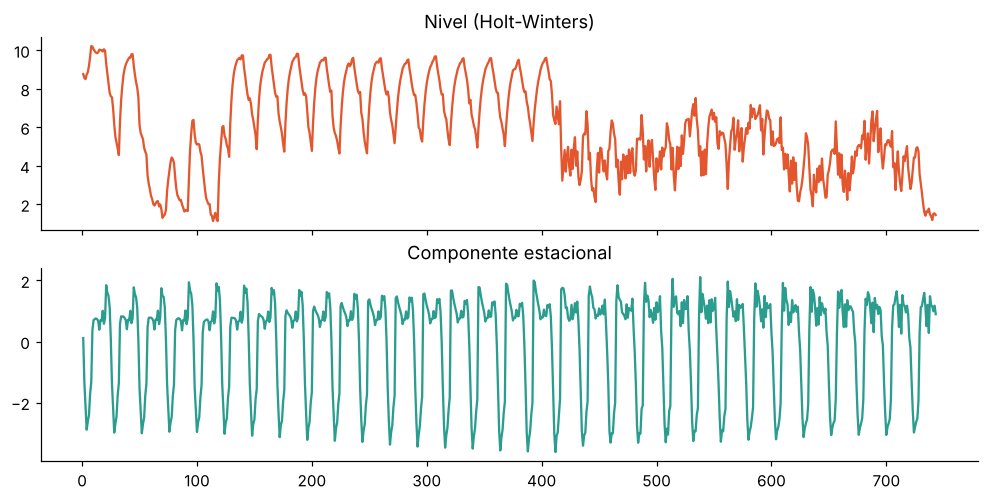

,modelo,m,alpha,gamma,beta,phi
0,HW_tend_amort_estac_adit_log1p,24,0.3359,0.0388,0.0001,0.8000


In [10]:
hw = o['hw_final']; L, B, S = hw.components(d[TARGET].to_numpy())
fig, axs = plt.subplots(2, 1, sharex=True, figsize=(11, 5)); axs[0].plot(d.step, L, color='#e4572e'); axs[0].set_title('Nivel (Holt-Winters)')
axs[1].plot(d.step, S, color='#2a9d8f'); axs[1].set_title('Componente estacional'); plt.show()
display(o['hw_params'])

## 8. Evaluación del modelo
Prueba: modelos reajustados con *train+validación*, evaluados **una sola vez**. Protocolo principal: pronóstico de 1 hora (parámetros congelados, estados actualizados con lo observado). Se reporta además el horizonte completo con origen fijo.

In [11]:
cols = ['modelo','familia','MAE','RMSE','MAPE_pct','WAPE_pct','R2']
display(o['test'][cols]); display(o['test_origen_fijo'][cols])
display(diag_test(o))   # sesgo y correlación en prueba

,modelo,familia,MAE,RMSE,MAPE_pct,WAPE_pct,R2
0,HW_tend_amort_estac_adit_log1p,holt_winters,811.4342,"1,601.9053","2,730.4623",112.7960,-0.0819
1,HW_sin_tend_estac_adit_log1p,holt_winters,811.4537,"1,601.7415","2,729.5710",112.7987,-0.0817
2,persistencia_1,baseline,"1,003.3333","1,800.7187","7,288.2068",139.4716,-0.3672
3,lineal_lags,regresion_lineal,"1,040.0608","1,702.5912","7,379.6361",144.5770,-0.2222
4,HW_sin_tend_estac_mult,holt_winters,"1,096.9745","2,046.3527","8,228.5320",152.4885,-0.7656
5,HW_tend_amort_estac_mult,holt_winters,"1,097.7861","2,048.5673","8,233.9017",152.6013,-0.7694
6,media_estacional_7,baseline,"1,282.3611","1,857.5965","9,711.5301",178.2587,-0.4549
7,lineal_temporal,regresion_lineal,"1,365.8415","1,946.8305","11,348.9157",189.8632,-0.5980
8,estacional_24,baseline,"1,421.3750","2,505.2972","7,401.1601",197.5828,-1.6463
9,estacional_168,baseline,"1,464.3056","2,694.9920","9,246.2102",203.5505,-2.0623


,modelo,familia,MAE,RMSE,MAPE_pct,WAPE_pct,R2
0,HW_tend_amort_estac_mult,holt_winters,"1,177.9669","1,740.4284","7,323.3110",163.7471,-0.2771
1,HW_sin_tend_estac_mult,holt_winters,"1,178.3233","1,741.3190","7,324.2018",163.7966,-0.2785
2,HW_tend_amort_estac_adit_log1p,holt_winters,"1,595.9817","2,414.3361","13,209.4787",221.8546,-1.4577
3,HW_sin_tend_estac_adit_log1p,holt_winters,"1,600.2644","2,420.7298","13,245.8277",222.4499,-1.4707
4,lineal_lags,regresion_lineal,"1,963.3508","2,242.7374","15,837.4358",272.9219,-1.1207
5,estacional_24,baseline,"2,047.7431","3,164.1674","16,365.6954",284.6531,-3.2213
6,lineal_temporal,regresion_lineal,"5,998.8753","7,956.2415","48,183.8577",833.8930,-25.6897
7,HW_sin_tend_estac_adit,holt_winters,"7,523.2273","10,225.9909","56,391.2108","1,045.7904",-43.0898
8,HW_tend_amort_estac_adit,holt_winters,"7,525.2183","10,228.3362","56,406.1359","1,046.0672",-43.1100


,modelo,pronostico_medio,sesgo_medio,correlacion
0,HW_tend_amort_estac_adit_log1p,292.6875,426.6944,0.2259
1,HW_sin_tend_estac_adit_log1p,293.1003,426.2816,0.2263
2,persistencia_1,731.9375,-12.5556,0.3171
3,lineal_lags,846.8813,-127.4994,0.2842
4,HW_sin_tend_estac_mult,815.4065,-96.0245,0.2805
5,HW_tend_amort_estac_mult,815.8425,-96.4606,0.2802
6,media_estacional_7,"1,396.6081",-677.2262,0.2713
7,lineal_temporal,"1,319.7230",-600.3411,0.2457
8,estacional_24,"1,125.1458",-405.7639,0.0180
9,estacional_168,"1,332.6736",-613.2917,0.2029


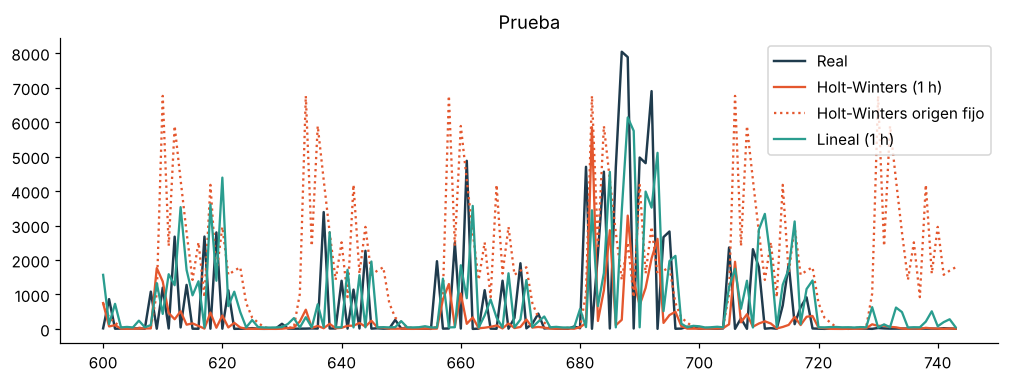

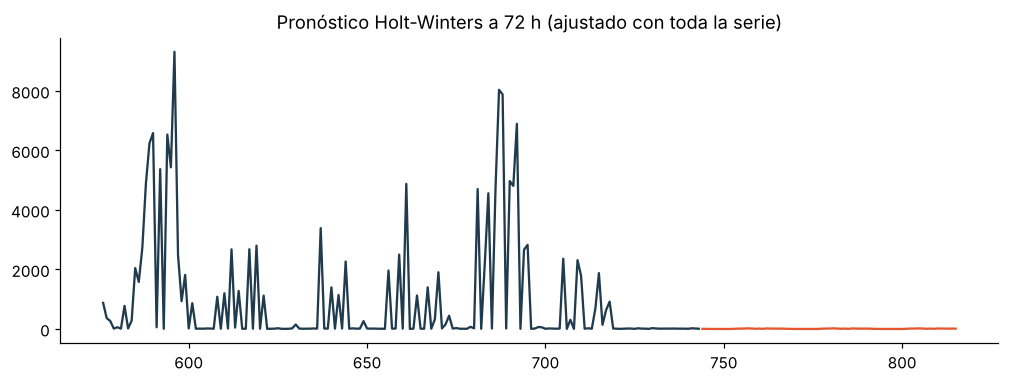

In [12]:
p = o['predictions']; te = p[p.bloque == 'test']; sel = o['selected']
fig, ax = plt.subplots(); ax.plot(te.step, te.real, color='#1f3b4d', lw=1.6, label='Real')
ax.plot(te.step, te[sel['holt_winters']], color='#e4572e', label='Holt-Winters (1 h)')
ax.plot(te.step, te[sel['holt_winters'] + '_origen_fijo'], color='#e4572e', ls=':', label='Holt-Winters origen fijo')
ax.plot(te.step, te[sel['lineal']], color='#2a9d8f', label='Lineal (1 h)'); ax.legend(); ax.set_title('Prueba'); plt.show()
fc = o['forecast_72']; h = d.tail(168); fig, ax = plt.subplots(); ax.plot(h.step, h[TARGET], color='#1f3b4d'); ax.plot(fc.step, fc.pronostico_HW, color='#e4572e')
ax.set_title('Pronóstico Holt-Winters a 72 h (ajustado con toda la serie)'); plt.show()

## 9. Conclusiones
(Generadas a partir de los resultados calculados arriba.)

In [13]:
for t in findings(o)['texto'] + findings(o)['alertas']: display(Markdown('- ' + t))
display(Markdown('- Limitaciones: serie simulada y corta, cambio de nivel entre bloques, conteos pequeños que inflan MAPE, un solo bloque de prueba y sin intervalos validados.'))

- En validación, el candidato Holt-Winters con menor MAE fue **HW_tend_amort_estac_adit_log1p** (MAE 2.002,17), y la regresión lineal seleccionada fue **lineal_lags** (MAE 1.938,37). La selección usó solo validación.

- En prueba (pronóstico de 1 hora con parámetros congelados) **HW_tend_amort_estac_adit_log1p** obtuvo MAE 811,43, RMSE 1.601,91, MAPE 2.730,46 % y R² -0,0819; **lineal_lags** obtuvo MAE 1.040,06 y R² -0,2222. Holt-Winters mejora a la regresión lineal en MAE y supera a la persistencia de 1 h (MAE 1.003,33); el baseline estacional de 24 h tuvo MAE 1.421,38.

- El mejor modelo por MAE en prueba, solo a modo descriptivo, fue **HW_tend_amort_estac_adit_log1p** (MAE 811,43); Holt-Winters quedó en la posición 1 de 13.

- Con origen fijo (144 h hacia adelante sin observar datos nuevos) el MAE de Holt-Winters fue 1.595,98 y el de la regresión lineal recursiva 1.963,35. Es una tarea más difícil que la de una hora; sus métricas no deben mezclarse.

- Un R² negativo indica un error cuadrático mayor que el de predecir con la media real del bloque de prueba; esa media no se conoce al pronosticar, así que el valor debe leerse como señal de dificultad (cambio de nivel, muchos conteos pequeños), no como un fallo del cálculo.

- **Selección en validación:** el mejor modelo global fue **estacional_24** (MAE 1.780,71); HW_tend_amort_estac_adit_log1p fue el mejor de su familia pero ocupó la posición 3 de 13 (MAE 2.002,17). Su resultado en prueba no se anticipaba en validación, así que no debe leerse como superioridad demostrada.

- **Referencia trivial:** pronosticar siempre 0 daría MAE 719,38 en prueba (la media del bloque; la mediana es 14,00), menor que el del mejor modelo (HW_tend_amort_estac_adit_log1p, 811,43). Ningún modelo supera esa referencia en MAE: con conteos concentrados cerca de cero el MAE premia a los pronósticos bajos. Por eso se reportan también R², el sesgo y la correlación con lo real.

- **Inestabilidad en validación cruzada:** HW_tend_amort_estac_adit_log1p tuvo MAE medio 15.036 (peor bloque 33.403) frente a 3.329 de lineal_lags. Las variantes sobre log(1+y) se retrotransforman con expm1, que amplifica de forma exponencial los errores tras un cambio de régimen; las variantes sin transformación (p. ej. multiplicativa) no mostraron ese problema. La ventaja en un único bloque de prueba no es evidencia suficiente para uso operativo.

- Limitaciones: serie simulada y corta, cambio de nivel entre bloques, conteos pequeños que inflan MAPE, un solo bloque de prueba y sin intervalos validados.